# Exploratory Data Analysis on Retail Sales Data

## Project Overview

This project explores a retail sales dataset containing 1,000 transactions and nine columns. The analysis focuses on understanding sales trends, customer demographics, product-category performance, and relationships between numerical variables.

## Objectives

- Inspect the dataset structure and assess data quality.
- Calculate descriptive statistics for numerical variables.
- Analyze monthly and quarterly sales trends.
- Examine transaction patterns across age groups and genders.
- Compare transaction counts and revenue across product categories.
- Investigate relationships between numerical variables using correlation analysis.
- Develop actionable business recommendations based on the findings.

## Dataset Overview

The dataset includes transaction dates, customer IDs, gender, age, product category, quantity purchased, price per unit, and total transaction amount.

In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#loading dataset
retail_data = pd.read_csv('retail_sales_dataset.csv')

In [3]:
#checking first five rows of the dataset
retail_data.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
#Checking the last five rows of the dataset
retail_data.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [5]:
#it shows the total number of rows and columns in the dataset.
retail_data.shape

(1000, 9)

In [6]:
#It provides infomation about the dataset like: number of entries, Dtypes and columns it's missing values
retail_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


### Descriptive Statistics

In [7]:
# Descriptive statistics for numerical columns
#print("Mean:\n", retail_data.mean(numeric_only=True))
#print("\nMedian:\n", retail_data.median(numeric_only=True))
#print("\nMode:\n", retail_data.mode(numeric_only=True))
#print("\nStandard Deviation:\n", retail_data.std(numeric_only=True))

#### Observations from Descriptive Statistics
*   **Transaction ID, Quantity, Price per Unit, Total Amount, Age**: These columns are numerical.
*   The mean, median, mode, and standard deviation give us a good overview of the central tendency and spread of these numerical features.
*   The mode for `Transaction ID` is all unique values, which is expected.
*   The standard deviation indicates the variability within each numerical column.

In [8]:
retail_data.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

# Descriptive Summary

In [9]:
#checking the summary statistics of numerical column in the dataset
retail_data.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [10]:
#checking missing values
retail_data.isnull().sum()


Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [11]:
#checking for duplicates
retail_data.duplicated().sum()

np.int64(0)

In [12]:
#renaming some column names
#retail_data['Gender'] = retail_data['Gender'].replace('male', 'Male')

In [13]:
retail_data[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].mean()

Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

In [14]:
retail_data[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].median()

Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

In [15]:
retail_data[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].mode().iloc[0]

Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

In [16]:
retail_data[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].std()

Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64

### Observations

- The average customer age is approximately 41 years, with ages ranging from 18 to 64.
- Customers purchase an average of about 2.5 items per transaction.
- The mean price per unit 179.89 is considerably higher than the median 50, indicating substantial variation in product prices.
- The mean total transaction amount 456 is higher than the median 135, suggesting that some transactions have relatively high values.
- The standard deviation of total amount 560 indicates considerable variation in transaction values.

In [17]:
retail_data['Date'] = pd.to_datetime(retail_data['Date'])

In [18]:
retail_data['Date'].dtype

dtype('<M8[ns]')

In [19]:
retail_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 70.4+ KB


In [20]:
#Monthly sales analysis
monthly_sales = retail_data.groupby(retail_data['Date'].dt.to_period('M'))['Total Amount'].sum()

In [21]:
monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

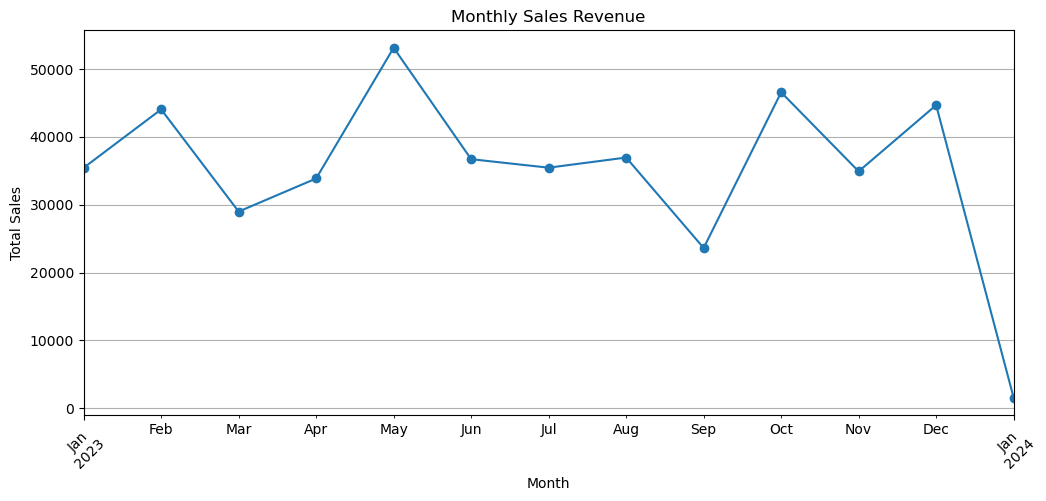

In [22]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Revenue')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Observations

- Monthly sales fluctuated throughout 2023, with no consistent upward or downward trend.
- May 2023 recorded the highest monthly sales at 53,150.
- September 2023 recorded the lowest sales among the full months of 2023 at 23,620.
- Sales increased substantially from September to October, reaching 46,580.
- December also recorded relatively high sales of 44,690.
- January 2024 recorded only 1,530 in sales. This value should be interpreted cautiously because the dataset appears to contain only a small number of transactions for that month.

In [23]:
quarterly_sales = retail_data.groupby(retail_data['Date'].dt.to_period('Q'))['Total Amount'].sum()

In [24]:
quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

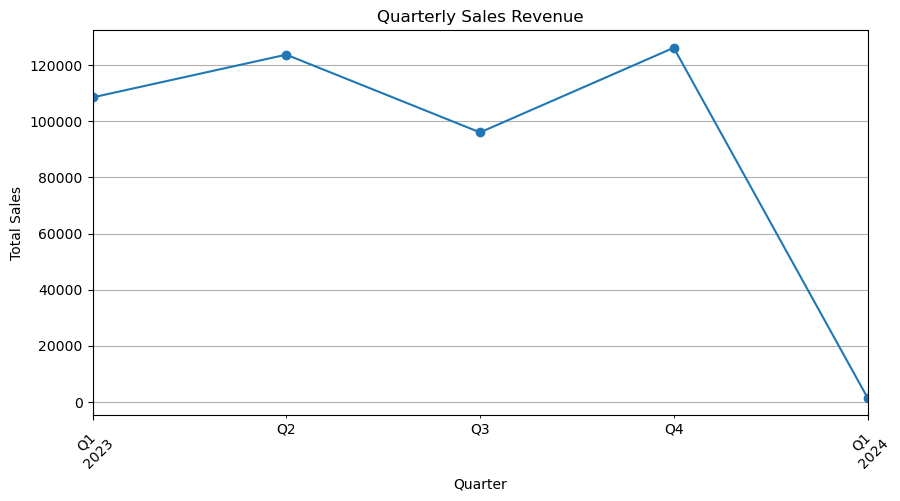

In [25]:
plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind='line', marker='o')

plt.title('Quarterly Sales Revenue')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Observations

- Quarterly sales fluctuated throughout 2023, with sales increasing from 108,500 in Q1 to 123,735 in Q2.
- Sales declined to 96,045 in Q3 before increasing to the highest quarterly sales of 126,190 in Q4.
- Q4 2023 recorded the highest sales among the complete quarters in the dataset.
- Q3 2023 recorded the lowest sales among the complete quarters of 2023.
- Q1 2024 recorded only 1,530 in sales because the dataset contains only January 2024 transactions, so this quarter should not be compared directly with the complete quarters of 2023.

In [26]:
age_bins = [17, 25, 35, 45, 55, 64]

age_labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

retail_data['Age Group'] = pd.cut(
    retail_data['Age'],
    bins=age_bins,
    labels=age_labels
)

In [27]:
retail_data['Age Group'].value_counts().sort_index()

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64

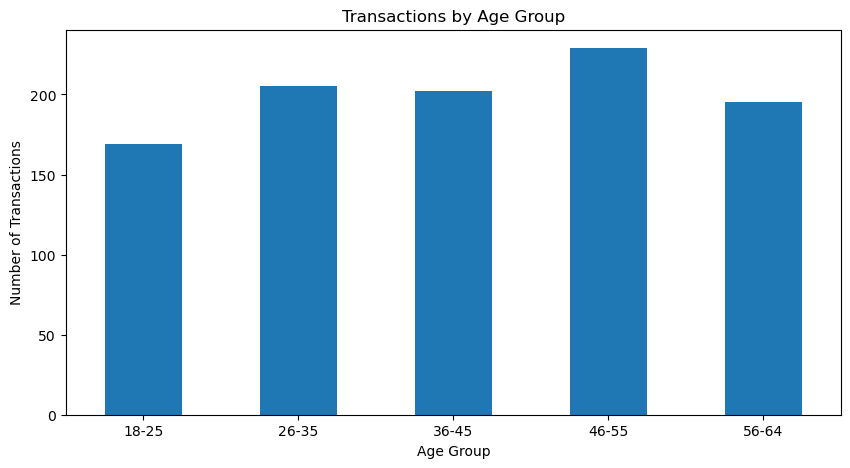

In [28]:
age_group_counts = retail_data['Age Group'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

age_group_counts.plot(kind='bar')

plt.title('Transactions by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)

plt.show()

### Observations

- The 46-55 age group recorded the highest number of transactions, with 229 transactions.
- The 18-25 age group recorded the lowest number of transactions, with 169 transactions.
- The remaining age groups had relatively similar transaction counts, ranging from 195 to 205.
- Overall, transactions were distributed fairly evenly across the different age groups.

### Gender Analysis

This section compares the number of transactions recorded for female and male customers to determine how transaction activity is distributed by gender.

In [29]:
#gender analysis
retail_data['Gender'].value_counts()

Gender
Female    510
Male      490
Name: count, dtype: int64

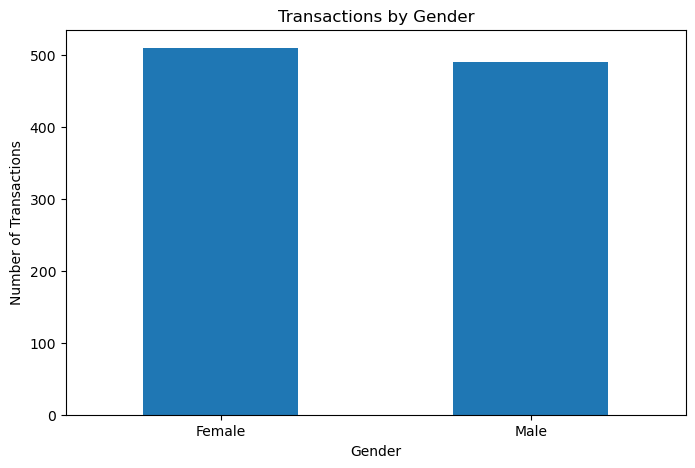

In [30]:
gender_counts = retail_data['Gender'].value_counts()

plt.figure(figsize=(8, 5))

gender_counts.plot(kind='bar')

plt.title('Transactions by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)

plt.show()

#### Observations

- Female customers accounted for 510 transactions, representing 51% of the dataset.
- Male customers accounted for 490 transactions, representing 49% of the dataset.
- Transaction activity was almost evenly distributed between the two gender groups.
- The small difference in transaction counts does not suggest a strong gender imbalance in this dataset.

## Product-Category Analysis

This section compares transaction counts and total revenue across Beauty, Clothing, and Electronics. Examining both measures helps distinguish the category with the most transactions from the category generating the highest total revenue.

In [31]:
retail_data['Product Category'].value_counts()

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

In [32]:
category_revenue = retail_data.groupby('Product Category')['Total Amount'].sum()

category_revenue

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

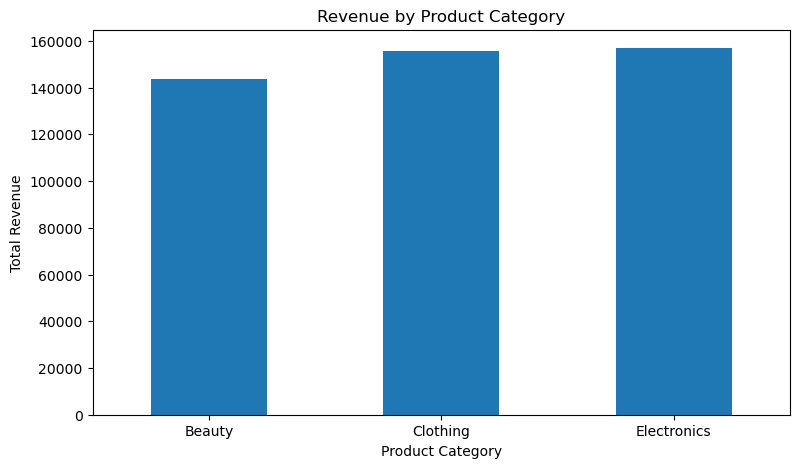

In [33]:
plt.figure(figsize=(9, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.show()

### Observations

- Electronics generated the highest total revenue at 156,905, contributing approximately 34.41% of total revenue.
- Clothing generated 155,580, contributing approximately 34.12% of total revenue.
- Beauty generated 143,515, contributing approximately 31.47% of total revenue.
- Clothing recorded the highest transaction count, with 351 transactions, while Electronics generated the highest revenue.
- Revenue was relatively evenly distributed across the three product categories.

### Dataset Limitation: Top 10 Products

The dataset contains a "Product Category" column but does not include a separate column identifying individual product names. Therefore, a Top 10 Products analysis could not be performed directly using the available fields.

Instead, sales performance was analyzed by product category, including transaction counts, total revenue, and revenue contribution. This provides a category-level view of performance while acknowledging the limitation of the dataset.

## Correlation Analysis

Correlation analysis is used to examine the direction and strength of linear relationships between numerical variables. The analysis focuses on Age, Quantity, Price per Unit, and Total Amount.

Correlation values range from -1 to +1. Positive values indicate that variables tend to move in the same direction, while negative values indicate that they tend to move in opposite directions. Values near zero indicate little or no linear relationship.

In [34]:
correlation_matrix = retail_data[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
].corr()

correlation_matrix

,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


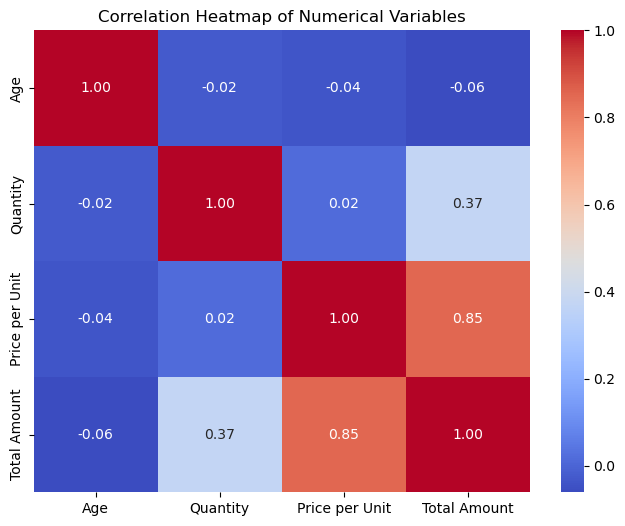

In [35]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Variables')

plt.show()

### Observations

- Price per Unit and Total Amount have a strong positive correlation of 0.85.
- Quantity and Total Amount show a moderate positive correlation of 0.37.
- Age has very weak correlations with Quantity, Price per Unit, and Total Amount.
- Quantity and Price per Unit have almost no linear correlation.
- The strong relationship between Price per Unit and Total Amount is expected because total transaction value is determined by the quantity purchased and the price per unit.

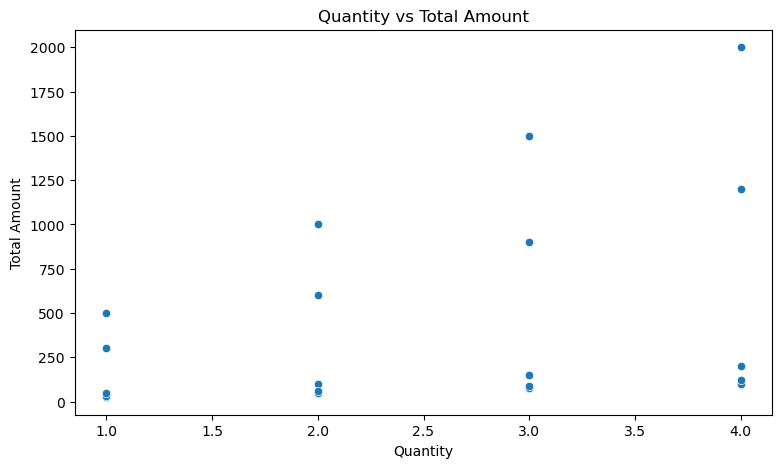

In [36]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=retail_data,
    x='Quantity',
    y='Total Amount'
)

plt.title('Quantity vs Total Amount')
plt.xlabel('Quantity')
plt.ylabel('Total Amount')

plt.show()

### Observations

- The scatter plot shows a positive relationship between Quantity and Total Amount.
- Higher quantities generally correspond to higher transaction amounts, although the points are widely spread.
- This is consistent with the correlation coefficient of 0.37, which indicates a moderate positive relationship.
- The relationship is not perfectly linear because Total Amount is also affected by the Price per Unit.

## Additional Analysis: Average Transaction Amount by Age Group

In addition to comparing transaction counts, this analysis examines the average transaction amount within each age group. It helps identify differences in average transaction value across the age ranges represented in the dataset.

In [37]:
avg_sales_age = retail_data.groupby('Age Group', observed=True)['Total Amount'].mean()

avg_sales_age

Age Group
18-25    500.295858
26-35    480.390244
36-45    454.801980
46-55    439.694323
56-64    412.358974
Name: Total Amount, dtype: float64

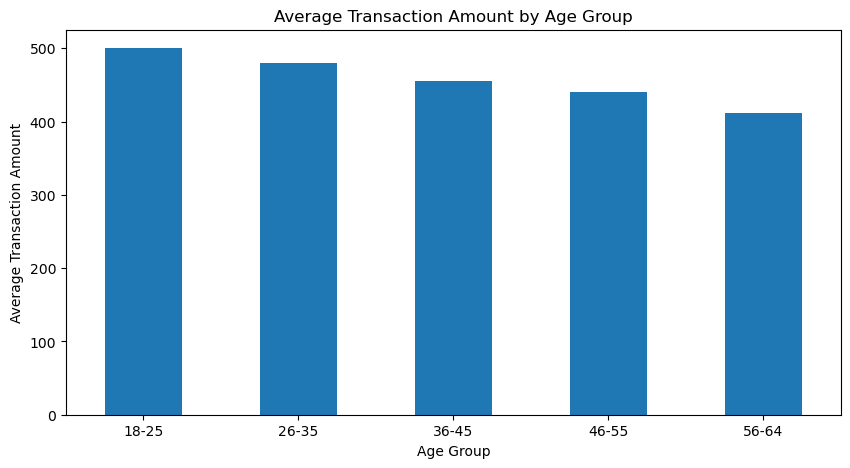

In [38]:
plt.figure(figsize=(10, 5))

avg_sales_age.plot(kind='bar')

plt.title('Average Transaction Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)

plt.show()

### Observations

- The 18-25 age group recorded the highest average transaction amount at approximately 500.30.
- The 56-64 age group recorded the lowest average transaction amount at approximately 412.36.
- Average transaction amount generally decreased across the age groups, from 500.30 among customers aged 18-25 to 412.36 among customers aged 56-64.
- This pattern represents an association observed in the dataset and does not necessarily imply that age directly causes differences in spending.

In [39]:
category_share = (category_revenue / category_revenue.sum()) * 100

category_share

Product Category
Beauty         31.472588
Clothing       34.118421
Electronics    34.408991
Name: Total Amount, dtype: float64

## Business Recommendations

1. **Focus promotional planning around stronger sales periods**
   - Q4 2023 recorded the highest quarterly revenue at 126,190, while May 2023 recorded the highest monthly revenue at 53,150.
   - The business can use stronger sales periods as a guide when planning promotions, inventory, and marketing campaigns.

2. **Maintain strong attention on Electronics and Clothing**
   - Electronics generated the highest revenue at 156,905 (34.41%), closely followed by Clothing at 155,580 (34.12%).
   - The business should monitor demand and inventory levels in these categories to support continued sales performance.

3. **Develop age-specific marketing strategies**
   - The 18-25 age group had the highest average transaction amount at approximately 500.30, while the 56-64 group had the lowest at approximately 412.36.
   - Marketing campaigns can be tailored to different age groups based on their observed purchasing patterns.

4. **Maintain marketing coverage across both genders**
   - Female transactions accounted for 51% of transactions, while male transactions accounted for 49%.
   - Since transaction activity is almost evenly divided, marketing strategies should continue to consider both customer groups rather than focusing heavily on one gender.

5. **Monitor pricing and transaction value**
   - Price per Unit had a strong positive correlation of 0.85 with Total Amount.
   - The business should monitor product pricing and its relationship with transaction value when evaluating revenue performance.

## Conclusion

The exploratory data analysis revealed several useful patterns in the retail sales dataset. Monthly sales fluctuated throughout 2023, with May recording the highest monthly revenue. At the quarterly level, Q4 2023 recorded the highest revenue among the complete quarters analyzed.

Electronics generated the highest revenue among the three product categories, while Clothing recorded the highest number of transactions. Transaction activity was also relatively balanced across genders. The age-group analysis showed that the 18–25 group had the highest average transaction amount, while the 56–64 group had the lowest.

The correlation analysis identified a strong positive relationship between price per unit and total transaction amount, alongside a moderate positive relationship between quantity and total amount. These relationships should be interpreted in light of how transaction values are calculated.

Overall, the analysis demonstrates how exploratory data analysis can help identify sales patterns, compare category performance, and support business decisions. However, the absence of individual product names limits the analysis of specific product performance.